In [1]:
import os
import json
import copy
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, wilcoxon
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from Bio.PDB.MMCIFParser import MMCIFParser
from Bio.PDB.SASA import ShrakeRupley
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# TF1-TF2 protein-protein buried surface area, high vs low motif syntax
# BSA = 0.5 * (SASA(TF1) + SASA(TF2) - SASA(TF1+TF2)), DNA chains excluded
# chains: A = TF1, B = TF2, C = DNA, D = revcomp DNA
dt = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv", dtype={"motif_combination": str})
manifest = dt[["motif_combination", "background_idx", "class", "TF1", "TF2"]].rename(columns={"motif_combination": "combo"})
manifest["group"] = manifest["TF1"] + "_" + manifest["TF2"] + "_" + manifest["combo"]
manifest["name"] = manifest["group"] + "_" + manifest["class"] + "_bg" + manifest["background_idx"].astype(str)
manifest["model_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_model.cif"
manifest["exists"] = manifest["model_path"].apply(os.path.exists)
manifest.head()

,combo,background_idx,class,TF1,TF2,group,name,model_path,exists
0,14_64,0,high,BCL11B,ETS1,BCL11B_ETS1_14_64,BCL11B_ETS1_14_64_high_bg0,outputs_n100_rho0.6/BCL11B_ETS1_14_64_high_bg0...,True
1,14_64,0,high,BCL11B,GABPA,BCL11B_GABPA_14_64,BCL11B_GABPA_14_64_high_bg0,outputs_n100_rho0.6/BCL11B_GABPA_14_64_high_bg...,True
2,14_64,0,high,BCL11B,IKZF1,BCL11B_IKZF1_14_64,BCL11B_IKZF1_14_64_high_bg0,outputs_n100_rho0.6/BCL11B_IKZF1_14_64_high_bg...,True
3,14_64,0,high,RUNX1,ETS1,RUNX1_ETS1_14_64,RUNX1_ETS1_14_64_high_bg0,outputs_n100_rho0.6/RUNX1_ETS1_14_64_high_bg0_...,True
4,14_64,0,high,RUNX1,GABPA,RUNX1_GABPA_14_64,RUNX1_GABPA_14_64_high_bg0,outputs_n100_rho0.6/RUNX1_GABPA_14_64_high_bg0...,True


In [3]:
manifest["exists"].value_counts()

exists
True    6400
Name: count, dtype: int64

In [4]:
manifest.groupby("class")["group"].nunique()

class
high    32
low     32
Name: group, dtype: int64

In [5]:
parser = MMCIFParser(QUIET=True)
sr = ShrakeRupley(probe_radius=1.4, n_points=100)

def yy_sasa(model, keep_chains):
    """Shrake-Rupley SASA (A^2) of a copy of the model with only keep_chains."""
    m = copy.deepcopy(model)
    for ch in list(m):
        if ch.id not in keep_chains:
            m.detach_child(ch.id)
    sr.compute(m, level="A")
    return sum(a.sasa for a in m.get_atoms())

In [6]:
# slow (~1h for 6,400 models), so resume from the checkpoint
checkpoint = "../results/cache/bsa_n100_rho0.6_checkpoint.csv"
records = pd.read_csv(checkpoint).to_dict("records") if os.path.exists(checkpoint) else []
todo = manifest[manifest["exists"] & ~manifest["name"].isin({r["name"] for r in records})]
print(f"{len(records)} done, {len(todo)} to do")

for i, (_, row) in enumerate(todo.iterrows()):
    model = parser.get_structure(row["name"], row["model_path"])[0]
    sasa_a = yy_sasa(model, {"A"})
    sasa_b = yy_sasa(model, {"B"})
    sasa_ab = yy_sasa(model, {"A", "B"})
    records.append({
        "name": row["name"], "group": row["group"], "combo": row["combo"],
        "background_idx": row["background_idx"], "class": row["class"],
        "TF1": row["TF1"], "TF2": row["TF2"], "pair": row["TF1"] + "-" + row["TF2"],
        "SASA_TF1": sasa_a, "SASA_TF2": sasa_b, "SASA_complex": sasa_ab,
        "BSA": 0.5 * (sasa_a + sasa_b - sasa_ab),
    })
    if (i + 1) % 200 == 0 or i + 1 == len(todo):
        pd.DataFrame(records).to_csv(checkpoint, index=False)

6400 done, 0 to do


In [7]:
results = pd.DataFrame(records)
results["class"] = pd.Categorical(results["class"], categories=["high", "low"], ordered=True)
results = results.sort_values(["class", "BSA"], ascending=[True, False]).reset_index(drop=True)

In [8]:
# TF1-TF2 (chain A-B) ipTM from the AF3 summary confidences
def yy_iptm(name, i, j):
    d = json.load(open(f"../af3_screen_n100_rho0.6/outputs_inference/{name}_summary_confidences.json"))
    return float(d["chain_pair_iptm"][i][j])

results["iptm_AB"] = results["name"].apply(lambda n: yy_iptm(n, 0, 1))

In [9]:
results.to_csv("../results/tables/bsa_n100_rho0.6_high_vs_low.csv", index=False)
results.to_csv("../results/tables/bsa_n100_rho0.6_high_vs_low_with_iptm.csv", index=False)
results.head()

,name,group,combo,background_idx,class,TF1,TF2,pair,SASA_TF1,SASA_TF2,SASA_complex,BSA,iptm_AB
0,BCL11B_ETS1_14_64_high_bg32,BCL11B_ETS1_14_64,14_64,32,high,BCL11B,ETS1,BCL11B-ETS1,78512.809676,38444.619458,104278.537000,6339.446067,0.33
1,BCL11B_ETS1_14_64_high_bg9,BCL11B_ETS1_14_64,14_64,9,high,BCL11B,ETS1,BCL11B-ETS1,75616.868205,31203.853588,95029.356652,5895.682571,0.33
2,BCL11B_ETS1_14_64_high_bg72,BCL11B_ETS1_14_64,14_64,72,high,BCL11B,ETS1,BCL11B-ETS1,73098.626860,35669.629593,97239.739912,5764.258270,0.33
3,BCL11B_ETS1_14_64_high_bg49,BCL11B_ETS1_14_64,14_64,49,high,BCL11B,ETS1,BCL11B-ETS1,71031.231380,35083.704392,94943.387522,5585.774125,0.33
4,BCL11B_ETS1_14_64_high_bg57,BCL11B_ETS1_14_64,14_64,57,high,BCL11B,ETS1,BCL11B-ETS1,74925.069598,35454.261240,99275.110751,5552.110043,0.32


In [10]:
results.groupby("class", observed=True)[["BSA", "iptm_AB"]].describe().T.round(2)

class             high      low
BSA     count  3200.00  3200.00
        mean   1240.18  1024.89
        std     803.50   760.98
        min      -0.00    -0.00
        25%     691.27   516.24
        50%    1116.42   854.93
        75%    1660.87  1316.05
        max    6339.45  4796.38
iptm_AB count  3200.00  3200.00
        mean      0.32     0.33
        std       0.09     0.09
        min       0.12     0.13
        25%       0.25     0.25
        50%       0.34     0.34
        75%       0.39     0.40
        max       0.55     0.51

In [11]:
# paired by background sequence: same background, motif swapped between high/low
paired = results.pivot_table(index=["group", "background_idx"], columns="class", values="BSA", observed=True)

stat, p_value = mannwhitneyu(results[results["class"] == "high"]["BSA"], results[results["class"] == "low"]["BSA"], alternative="two-sided")
print(f"BSA Mann-Whitney U stat = {stat:.2f}, p-value = {p_value:.3e}")
stat, p_value = wilcoxon(paired["high"], paired["low"], alternative="two-sided")
print(f"BSA paired Wilcoxon stat = {stat:.2f}, p-value = {p_value:.3e}, n pairs = {len(paired)}")
print(f"mean high = {paired['high'].mean():.1f}, mean low = {paired['low'].mean():.1f}")

BSA Mann-Whitney U stat = 6105332.00, p-value = 1.506e-40
BSA paired Wilcoxon stat = 1663798.00, p-value = 5.149e-66, n pairs = 3200
mean high = 1240.2, mean low = 1024.9


In [12]:
stat, p_value = mannwhitneyu(results[results["class"] == "high"]["iptm_AB"], results[results["class"] == "low"]["iptm_AB"], alternative="two-sided")
print(f"ipTM AB Mann-Whitney U stat = {stat:.2f}, p-value = {p_value:.3e}")

ipTM AB Mann-Whitney U stat = 4954670.00, p-value = 2.518e-02


In [13]:
palette = {"high": "#2b8cbe", "low": "#e34a33"}

def yy_boxstrip(df, y, ax):
    sns.boxplot(data=df, x="class", y=y, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=df, x="class", y=y, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.3, ax=ax)

def yy_group_bar(df, y, ax, ascending=False):
    """Per TF1-TF2-combo group mean +/- SD over backgrounds, high vs low."""
    grp = df.groupby(["group", "class"], observed=True)[y].agg(["mean", "std"]).reset_index()
    groups = df.groupby("group")[y].mean().sort_values(ascending=ascending).index
    x = np.arange(len(groups))
    for j, cls in enumerate(["high", "low"]):
        sub = grp[grp["class"] == cls].set_index("group").reindex(groups)
        ax.bar(x + (j - 0.5) * 0.4, sub["mean"], 0.4, yerr=sub["std"], color=palette[cls], label=cls,
               capsize=2, error_kw={"lw": 0.8})
    labels = df.drop_duplicates("group").set_index("group").loc[groups]
    ax.set_xticks(x)
    ax.set_xticklabels(labels["pair"] + "\n(" + labels["combo"] + ")", rotation=90, fontsize=7)
    ax.legend(title="class")

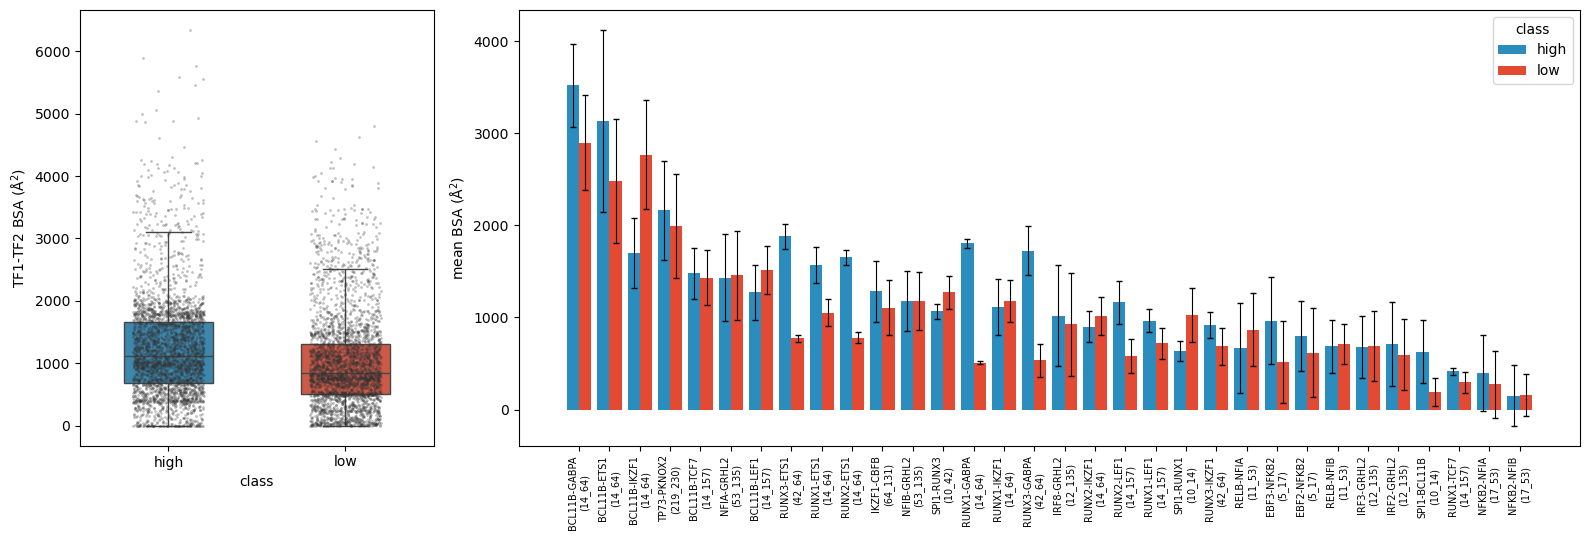

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 3]})
yy_boxstrip(results, "BSA", axes[0])
axes[0].set_ylabel("TF1-TF2 BSA (Å$^2$)")
yy_group_bar(results, "BSA", axes[1])
axes[1].set_ylabel("mean BSA (Å$^2$)")
plt.tight_layout()
plt.savefig("../results/figures/bsa_n100_rho0.6_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

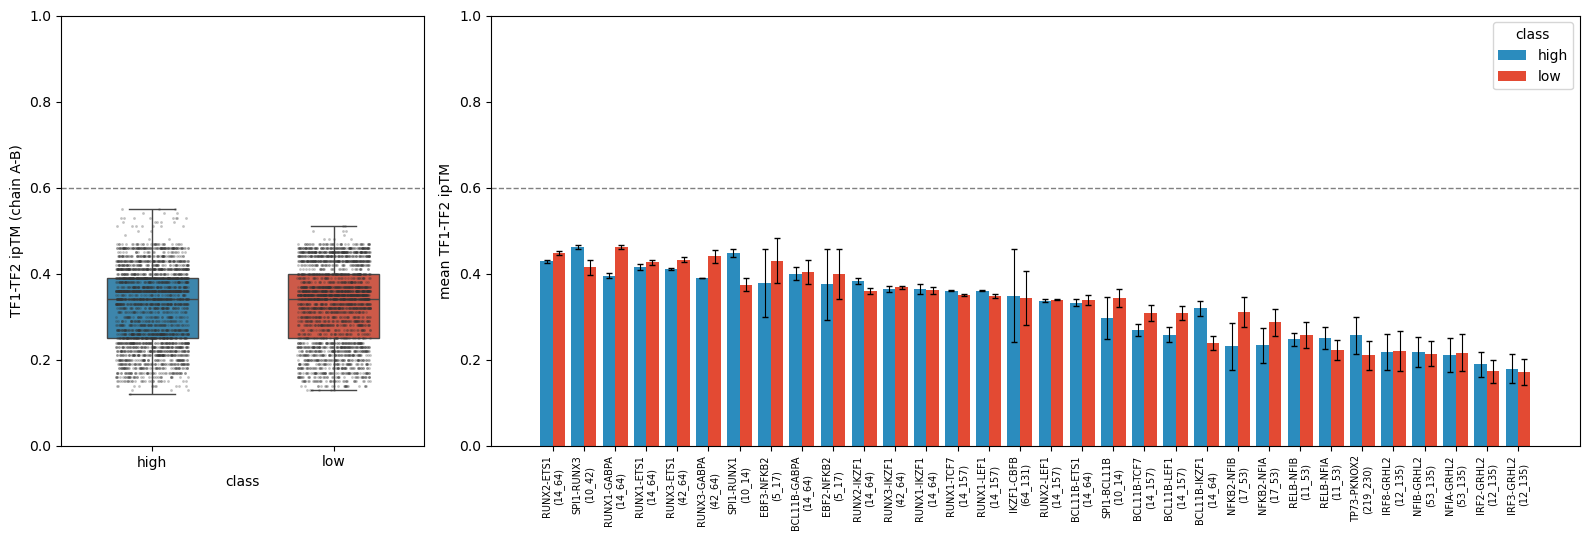

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 3]})
yy_boxstrip(results, "iptm_AB", axes[0])
axes[0].set_ylabel("TF1-TF2 ipTM (chain A-B)")
yy_group_bar(results, "iptm_AB", axes[1])
axes[1].set_ylabel("mean TF1-TF2 ipTM")
for ax in axes:
    ax.axhline(0.6, ls="--", color="grey", lw=1)
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("../results/figures/iptm_n100_rho0.6_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

0/6400 models with iptm_AB >= 0.6


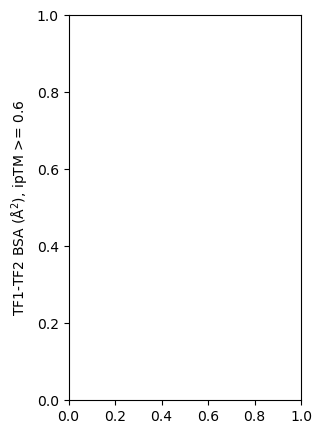

In [16]:
results_iptm6 = results[results["iptm_AB"] >= 0.6]
print(f"{len(results_iptm6)}/{len(results)} models with iptm_AB >= 0.6")

fig, ax = plt.subplots(figsize=(3, 5))
yy_boxstrip(results_iptm6, "BSA", ax)
ax.set_ylabel("TF1-TF2 BSA (Å$^2$), ipTM >= 0.6")
plt.show()
plt.close()

In [17]:
# BSA vs ipTM: between TF-pair groups (n=32 group means) vs within group (demeaned per group)
# pooled r mixes the two, so report them separately
for cls, g in results.groupby("class", observed=True):
    g = g.copy()
    gm = g.groupby("group")[["BSA", "iptm_AB"]].mean()
    r_between, p_between = stats.pearsonr(gm["BSA"], gm["iptm_AB"])
    g["BSA_c"] = g["BSA"] - g.groupby("group")["BSA"].transform("mean")
    g["iptm_c"] = g["iptm_AB"] - g.groupby("group")["iptm_AB"].transform("mean")
    r_within, p_within = stats.pearsonr(g["BSA_c"], g["iptm_c"])
    r_sp, p_sp = stats.spearmanr(g["BSA_c"], g["iptm_c"])
    r_pooled, p_pooled = stats.pearsonr(g["BSA"], g["iptm_AB"])
    # OLS with group fixed effects should give the same partial r as demeaning
    t = smf.ols("iptm_AB ~ BSA + C(group)", data=g).fit()
    r_ols = t.tvalues["BSA"] / np.sqrt(t.tvalues["BSA"] ** 2 + t.df_resid)
    print(f"{cls}: pooled r = {r_pooled:+.3f} (p = {p_pooled:.2e}), "
          f"between r = {r_between:+.3f} (p = {p_between:.3g}, n = {len(gm)}), "
          f"within r = {r_within:+.3f} (p = {p_within:.3g}, OLS-FE r = {r_ols:+.3f}), "
          f"within Spearman = {r_sp:+.3f} (p = {p_sp:.3g})")

high: pooled r = +0.236 (p = 1.21e-41), between r = +0.289 (p = 0.108, n = 32), within r = +0.003 (p = 0.863, OLS-FE r = +0.003), within Spearman = +0.086 (p = 1.15e-06)
low: pooled r = -0.107 (p = 1.28e-09), between r = -0.145 (p = 0.428, n = 32), within r = +0.115 (p = 8.2e-11, OLS-FE r = +0.115), within Spearman = +0.195 (p = 7.96e-29)


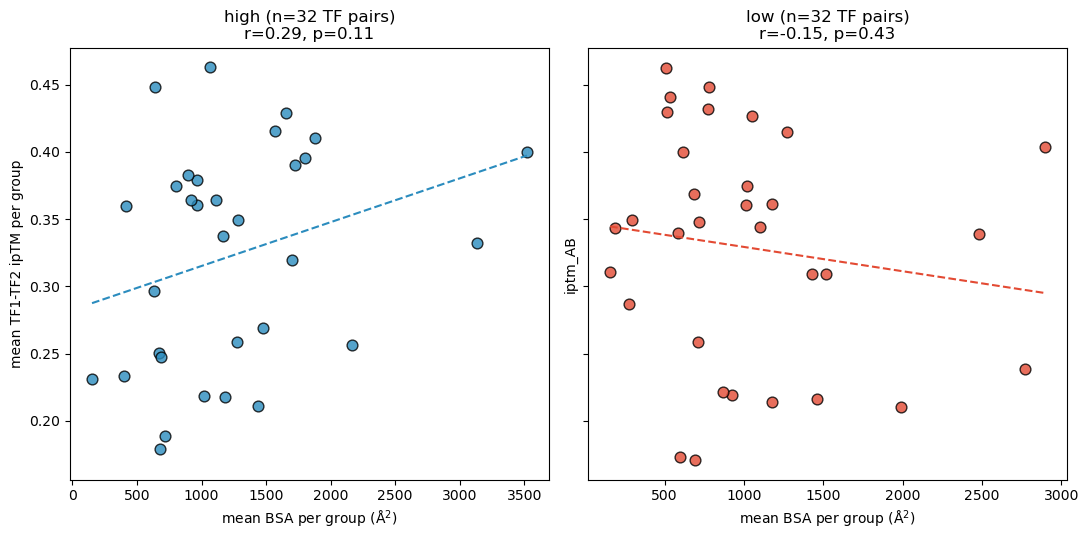

In [18]:
gm_by_class = results.groupby(["group", "class"], observed=True)[["BSA", "iptm_AB"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
for ax, cls in zip(axes, ["high", "low"]):
    g = gm_by_class[gm_by_class["class"] == cls]
    sns.regplot(data=g, x="BSA", y="iptm_AB", color=palette[cls], ci=None, ax=ax,
                scatter_kws={"s": 60, "edgecolor": "k"}, line_kws={"ls": "--", "lw": 1.5})
    r, p = stats.pearsonr(g["BSA"], g["iptm_AB"])
    ax.set_title(f"{cls} (n={len(g)} TF pairs)\nr={r:.2f}, p={p:.2f}")
    ax.set_xlabel("mean BSA per group (Å$^2$)")
axes[0].set_ylabel("mean TF1-TF2 ipTM per group")
plt.tight_layout()
plt.savefig("../results/figures/between_group_bsa_iptm_scatter.pdf", bbox_inches='tight')
plt.show()
plt.close()

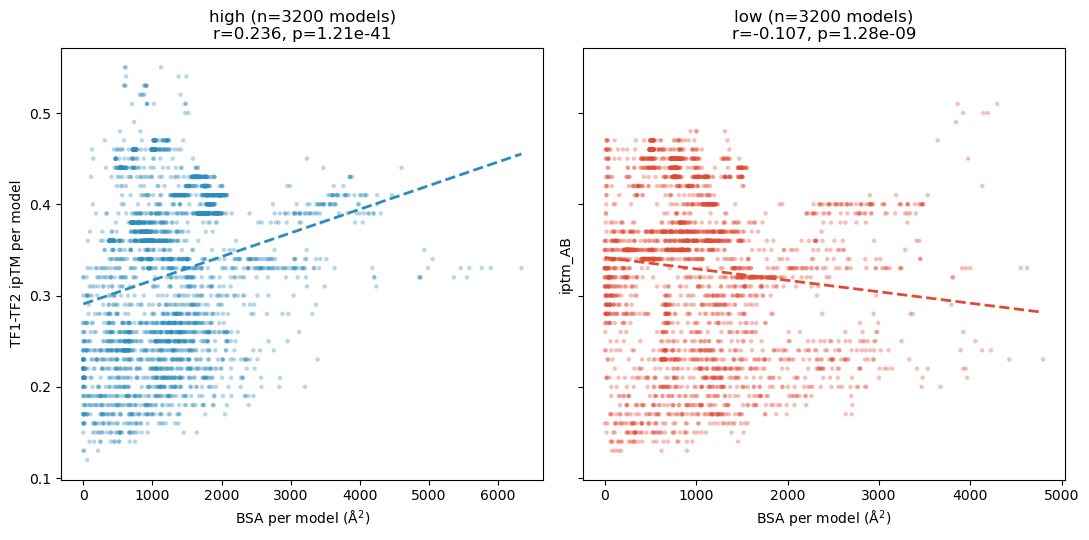

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
for ax, cls in zip(axes, ["high", "low"]):
    g = results[results["class"] == cls]
    sns.regplot(data=g, x="BSA", y="iptm_AB", color=palette[cls], ci=None, ax=ax,
                scatter_kws={"s": 10, "alpha": 0.35, "edgecolor": "none"}, line_kws={"ls": "--", "lw": 2})
    r, p = stats.pearsonr(g["BSA"], g["iptm_AB"])
    ax.set_title(f"{cls} (n={len(g)} models)\nr={r:.3f}, p={p:.2e}")
    ax.set_xlabel("BSA per model (Å$^2$)")
axes[0].set_ylabel("TF1-TF2 ipTM per model")
plt.tight_layout()
plt.savefig("../results/figures/full_dataset_bsa_iptm_scatter.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [20]:
# per TF-pair group: paired Wilcoxon (high vs low, matched by background_idx), BH FDR over the 32 groups
rows = []
for grp, g in results.groupby("group"):
    hi = g[g["class"] == "high"].set_index("background_idx")["BSA"]
    lo = g[g["class"] == "low"].set_index("background_idx")["BSA"]
    common = hi.index.intersection(lo.index).sort_values()
    diff = hi.loc[common] - lo.loc[common]
    stat, p = wilcoxon(hi.loc[common], lo.loc[common], alternative="two-sided")
    rows.append({"group": grp, "combo": g["combo"].iloc[0], "n_pairs": len(common),
                 "mean_diff": diff.mean(), "n_high_gt_low": int((diff > 0).sum()),
                 "n_low_gt_high": int((diff < 0).sum()), "wilcoxon_p": p})

pair_test = pd.DataFrame(rows).sort_values("wilcoxon_p")
pair_test["fdr_sig"] = multipletests(pair_test["wilcoxon_p"], alpha=0.05, method="fdr_bh")[0]
pair_test["category"] = np.where(~pair_test["fdr_sig"], "no significant difference",
                                 np.where(pair_test["mean_diff"] > 0, "high > low (good motif wins)", "low > high (REVERSE)"))
pair_test.to_csv("../results/tables/per_group_paired_bsa_test.csv", index=False)
pair_test

,group,combo,n_pairs,mean_diff,n_high_gt_low,n_low_gt_high,wilcoxon_p,fdr_sig,category
25,RUNX3_ETS1_42_64,42_64,100,1107.574302,100,0,3.896560e-18,True,high > low (good motif wins)
26,RUNX3_GABPA_42_64,42_64,100,1193.903671,100,0,3.896560e-18,True,high > low (good motif wins)
22,RUNX2_ETS1_14_64,14_64,100,872.827891,100,0,3.896560e-18,True,high > low (good motif wins)
18,RUNX1_GABPA_14_64,14_64,100,1296.358563,100,0,3.896560e-18,True,high > low (good motif wins)
17,RUNX1_ETS1_14_64,14_64,100,514.380905,99,1,4.139374e-18,True,high > low (good motif wins)
2,BCL11B_IKZF1_14_64,14_64,100,-1071.900456,3,97,9.601771e-18,True,low > high (REVERSE)
24,RUNX2_LEF1_14_157,14_157,100,579.212812,92,8,1.255922e-17,True,high > low (good motif wins)
29,SPI1_RUNX1_10_14,10_14,100,-385.478550,5,95,3.976798e-17,True,low > high (REVERSE)
30,SPI1_RUNX3_10_42,10_42,100,-206.538723,10,90,2.328220e-16,True,low > high (REVERSE)
28,SPI1_BCL11B_10_14,10_14,100,440.351600,93,7,4.001558e-16,True,high > low (good motif wins)


In [21]:
pair_test["category"].value_counts()

category
high > low (good motif wins)    16
low > high (REVERSE)             9
no significant difference        7
Name: count, dtype: int64

In [22]:
# roll up to motif combination: does at least one TF pair show high > low?
per_combo = pair_test.groupby("combo").agg(
    n_tf_pairs=("group", "count"),
    n_good=("category", lambda s: (s == "high > low (good motif wins)").sum()),
    n_reverse=("category", lambda s: (s == "low > high (REVERSE)").sum()),
    n_ns=("category", lambda s: (s == "no significant difference").sum()),
).reset_index()
per_combo["has_at_least_one_good"] = per_combo["n_good"] > 0
per_combo.to_csv("../results/tables/per_combo_paired_bsa_summary.csv", index=False)
per_combo

,combo,n_tf_pairs,n_good,n_reverse,n_ns,has_at_least_one_good
0,10_14,2,1,1,0,True
1,10_42,1,0,1,0,False
2,11_53,2,0,2,0,False
3,12_135,3,0,0,3,False
4,14_157,5,3,1,1,True
5,14_64,8,5,3,0,True
6,17_53,2,1,1,0,True
7,219_230,1,0,0,1,False
8,42_64,3,3,0,0,True
9,53_135,2,0,0,2,False


In [23]:
per_combo["has_at_least_one_good"].value_counts()

has_at_least_one_good
True     7
False    5
Name: count, dtype: int64